# Warm-up duration

OpenSARShip2 · ResNet-18 · Supplementary Note S7

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/s7_length.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from gw import duration, presentation
config = presentation.read_experiment(ROOT, 's7_length')
runs, summary = duration.summarize(ROOT, config)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Validation · 954 images · mean ± sample SD · 3 paired seeds.

In [2]:
duration.show_table(summary)

,ECE (%) ↓
Warm-up epochs,
0,5.86 ± 0.95
1,5.58 ± 0.61
2,5.10 ± 0.95
3,5.12 ± 1.09
4,4.27 ± 0.20
5,6.31 ± 3.35
6,5.39 ± 0.61
7,6.17 ± 2.31
8,5.58 ± 1.91


## Calibration

Diamonds: mean; bars: sample SD; circles: individual runs.

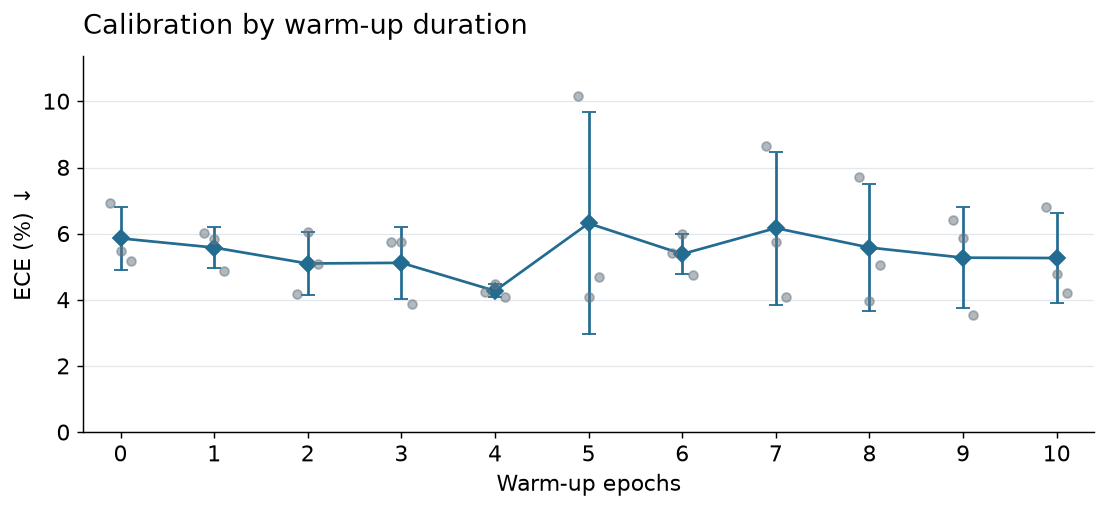

In [3]:
figure = duration.plot(runs, summary, ROOT / 'assets/figures/s7_length_ece.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Settings

GW · L = 1 · p = 0.5 · ρ = 0.25 · warm-up: 0–10 epochs · supervised training: 50 epochs.

<details><summary>Seeds and configuration</summary>

Seeds: 20262101–20262103. [Configuration](../configs/s7_length.json).

</details>

## Reference values

Calculated from saved per-image predictions.

In [4]:
check = duration.comparison(ROOT, summary)
folded_comparison(check)

,Paper ECE (%),Recomputed ECE (%),Δ mean (pp)
Warm-up epochs,,,
0,5.86 ± 0.95,5.86 ± 0.95,0.000640443
1,5.58 ± 0.61,5.58 ± 0.61,0.00190266
2,5.10 ± 0.95,5.10 ± 0.95,0.0003058
3,5.12 ± 1.09,5.12 ± 1.09,0.000627048
4,4.28 ± 0.20,4.27 ± 0.20,-0.00528227
5,6.31 ± 3.35,6.31 ± 3.35,0.00404975
6,5.39 ± 0.61,5.39 ± 0.61,-0.0032715
7,6.17 ± 2.31,6.17 ± 2.31,0.00109677
8,5.58 ± 1.92,5.58 ± 1.91,0.00276681


## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [5]:
RUN_INFERENCE = False
if RUN_INFERENCE:
    from gw.inference import run_experiment
    prediction_directory = run_experiment(ROOT, config)
else:
    prediction_directory = ROOT / 'results/s7_length/gpu_predictions'
if RUN_INFERENCE:
    inference_runs, inference_summary = duration.summarize(ROOT, config, prediction_directory)
    folded_comparison(duration.comparison(ROOT, inference_summary))

## Training

Optional · one seed and condition · validation NLL selection. Set `RUN_TRAINING = True` to run.

In [6]:
import json
import pandas as pd
RUN_TRAINING = False
TRAIN_RUN = 'w05_20262101'

training_config = json.loads((ROOT / 'configs/ablation_training.json').read_text())
matches = [run for run in training_config['runs']
           if run['experiment'] == 's7_length' and run['id'] == TRAIN_RUN]
if len(matches) != 1:
    raise ValueError('Choose a run ID from configs/ablation_training.json')
selected_run = matches[0]
labels = {condition['id']: condition['label'] for condition in config['conditions']}
selection = pd.DataFrame([{
    'Condition': labels[selected_run['condition']],
    'Seed': selected_run['seed'],
    'Warm-up epochs': selected_run['warmup_epochs'],
    'Training epochs': selected_run['supervised_epochs']
}])
display(selection.style.hide(axis='index'))

if RUN_TRAINING:
    from gw.ablation_training import train
    training_directory = train(ROOT, selected_run, device='auto')
    training_record = json.loads((training_directory / 'run.json').read_text())
    validation = training_record['validation']
    result = pd.DataFrame([{'Seed': selected_run['seed'],
                            'Selected epoch': training_record['best_epoch'],
                            'ECE (%)': 100 * validation['ece_15'],
                            'NLL': validation['nll']}])
    display(result.style.hide(axis='index').format({'ECE (%)': '{:.2f}', 'NLL': '{:.4f}'}))
    print(training_directory)


Condition,Seed,Warm-up epochs,Training epochs
5,20262101,5,50
